### 1. Importing the main libraries

In [1]:
import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from pathlib import Path

### 2. Loading data from Kaggle, unzipping, and creating a DataFrame

In [ ]:
kagglehub.login()

In [3]:
path = kagglehub.dataset_download(
    "hamdallak/the-iqothnccd-lung-cancer-dataset"
)

print("Path to dataset:", path)

Using Colab cache for faster access to the 'the-iqothnccd-lung-cancer-dataset' dataset.
Path to dataset: /kaggle/input/the-iqothnccd-lung-cancer-dataset


In [4]:
for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    if os.path.isdir(folder_path):
        print(f"Folder: {folder}")
        print(f"Path: {folder_path}")
        print(f"Number of files: {len(os.listdir(folder_path))}")

Folder: The IQ-OTHNCCD lung cancer dataset
Path: /kaggle/input/the-iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset
Number of files: 4


In [5]:
# Feature Merging
def path_finder(base_path):

    targets = {
        "normal cases": "Normal",
        "bengin cases": "Benign",
        "malignant cases": "Malignant"
    }

    paths = {}

    for root, dirs, _ in os.walk(base_path):
        for folder in dirs:
            folder_clean = folder.lower().strip()
            if folder_clean in targets:
                class_name = targets[folder_clean]
                paths[class_name] = os.path.join(root, folder)

    return paths

paths = path_finder(path)

In [6]:
# Creating a DataFrame
data = []

for label, folder_path in paths.items():
    for f in os.listdir(folder_path):
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(folder_path, f)
            data.append({"image_path": full_path, "label": label})

df = pd.DataFrame(data)
df.head()

,image_path,label
0,/kaggle/input/the-iqothnccd-lung-cancer-datase...,Normal
1,/kaggle/input/the-iqothnccd-lung-cancer-datase...,Normal
2,/kaggle/input/the-iqothnccd-lung-cancer-datase...,Normal
3,/kaggle/input/the-iqothnccd-lung-cancer-datase...,Normal
4,/kaggle/input/the-iqothnccd-lung-cancer-datase...,Normal


In [7]:
import re

def extract_group(path):
  name = os.path.basename(path)
  match = re.search(r'(case\s*\(\d+\)|patient[_\d]+|\d+)', name, re.IGNORECASE)
  if match:
      return match.group(0).lower()
  return name.split('.')[0]

df["group"] = df["image_path"].apply(extract_group)

In [8]:
print(df.columns.tolist())

['image_path', 'label', 'group']


In [9]:
df["label"] = np.where(df["label"] == "Normal", "Normal", "Abnormal")
print(df["label"].value_counts())

label
Abnormal    681
Normal      416
Name: count, dtype: int64


### 3. Plotting Data Ratios

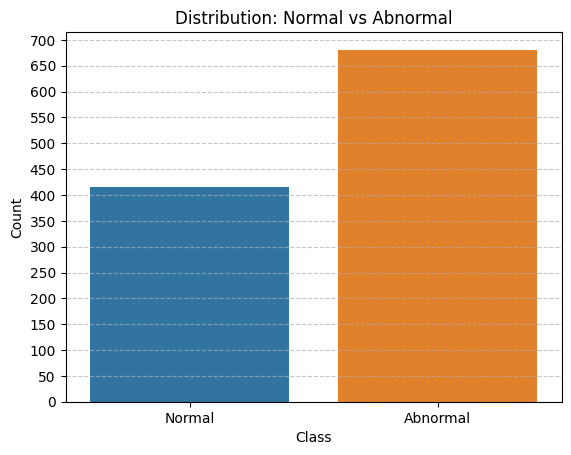

In [10]:
sns.countplot(data=df, x='label', hue='label')
plt.title("Distribution: Normal vs Abnormal")
plt.xlabel("Class")
plt.ylabel("Count")
plt.yticks(range(0, 701, 50))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 4. Segmentation and Creation of Image Data

In [11]:
import os, re
from sklearn.model_selection import StratifiedGroupKFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.applications.densenet import preprocess_input

BLOCK = 10

df["orig_class"] = df["image_path"].apply(
    lambda p: os.path.basename(os.path.dirname(p)).lower().strip()
)
df["num"] = df["image_path"].apply(
    lambda p: int(re.findall(r"\d+", os.path.basename(p))[-1])
)
df["group"] = df["orig_class"] + "_" + (df["num"] // BLOCK).astype(str)

# split
sg1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=10)
trainval_idx, test_idx = next(sg1.split(df, df["label"], groups=df["group"]))
trainval_df, test_df = df.iloc[trainval_idx], df.iloc[test_idx]

sg2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=10)
train_idx, val_idx = next(sg2.split(trainval_df, trainval_df["label"], groups=trainval_df["group"]))
train_df, val_df = trainval_df.iloc[train_idx], trainval_df.iloc[val_idx]

G = lambda d: set(d["group"])
print(len(G(train_df) & G(val_df)), len(G(train_df) & G(test_df)), len(G(val_df) & G(test_df)))
print(len(train_df), len(val_df), len(test_df))

# generators
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

common = dict(
    x_col='image_path',
    y_col='label',
    classes=['Abnormal', 'Normal'],
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

train_generator = train_datagen.flow_from_dataframe(dataframe=train_df, **common)
val_generator   = eval_datagen.flow_from_dataframe(dataframe=val_df, shuffle=False, **common)
test_generator  = eval_datagen.flow_from_dataframe(dataframe=test_df, shuffle=False, **common)

0 0 0
658 220 219
Found 658 validated image filenames belonging to 2 classes.
Found 220 validated image filenames belonging to 2 classes.
Found 219 validated image filenames belonging to 2 classes.


### 5. Central Model:
* Placing a pre-made model
* adding hand-crafted layers
* model training

In [12]:
from keras.applications import DenseNet121

base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    name = "DenseNet121"
)

base_model.trainable = True

base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

In [13]:
from keras.layers import Dropout, BatchNormalization, Conv2D, Dense, GlobalAveragePooling2D
from keras import models, layers

inputs = layers.Input(shape=(224, 224, 3), name="input_img")

x = layers.RandomFlip('horizontal')(inputs)
x = layers.RandomRotation(0.05)(x)

x = base_model(inputs = x, training=False)

x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.25)(x)

x = Dense(units=256, activation='relu')(x)
x = Dropout(0.25)(x)
x = Dense(units=128, activation='relu')(x)
x = Dropout(0.25)(x)
x = Dense(units=64, activation='relu')(x)
x = Dropout(0.25)(x)
outputs = Dense(units=1, activation='sigmoid')(x)

model = models.Model(inputs=inputs, outputs=outputs, name="DenseNet121")

In [14]:
model.summary()

Model: "DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_img (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseNet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,345,217 (28.02 MB)

 Trainable params: 672,833 (2.57 MB)

 Non-trainable params: 6,672,384 (25.45 MB)

In [15]:
import keras

model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

In [16]:
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping

callbacks = [
    ModelCheckpoint('best_lung_ct_model_phase1.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5, mode='min', verbose=1),
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
]

model.fit(
    train_generator,
    epochs=12,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/12
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step - accuracy: 0.5683 - auc: 0.5675 - loss: 0.7050
Epoch 1: val_loss improved from None to 0.58374, saving model to best_lung_ct_model_phase1.keras

Epoch 1: finished saving model to best_lung_ct_model_phase1.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 52s 848ms/step - accuracy: 0.6216 - auc: 0.6424 - loss: 0.6497 - val_accuracy: 0.8182 - val_auc: 0.8821 - val_loss: 0.5837 - learning_rate: 1.0000e-04
Epoch 2/12
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.7694 - auc: 0.8427 - loss: 0.4861
Epoch 2: val_loss improved from 0.58374 to 0.50960, saving model to best_lung_ct_model_phase1.keras

Epoch 2: finished saving model to best_lung_ct_model_phase1.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 465ms/step - accuracy: 0.7857 - auc: 0.8686 - loss: 0.4592 - val_accuracy: 0.8136 - val_auc: 0.9130 - val_loss: 0.5096 - learning_rate: 1.0000e-04
Epoch 3/12
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.7981 - auc: 0.8853 - loss: 0.4211
Epoch 3: val_

### 6. Model Evaluation:
* Model Performance Evaluation
* model testing
* Drawing Conclusions

In [17]:
print(model.history.history.keys())

dict_keys(['accuracy', 'auc', 'loss', 'val_accuracy', 'val_auc', 'val_loss', 'learning_rate'])


In [18]:
history = model.history.history

In [19]:
results = model.evaluate(val_generator)

for name, val in zip(model.metrics_names, results):
    print(f"Test {name}: {val:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 234ms/step - accuracy: 0.8545 - auc: 0.9126 - loss: 0.3739
Test loss: 0.3739
Test compile_metrics: 0.8545


In [20]:
import plotly.express as px
import plotly
import plotly.io as pio

epochs = list(range(1, len(history['loss']) + 1))

fig_loss = px.line(
    x=epochs,
    y=[history['loss'], history['auc'], history['accuracy'], history['val_accuracy'], history['val_auc'], history['val_loss']],
    labels={'x': 'Epoch', 'value': 'Loss', 'variable': 'Dataset'},
    markers=True
)

names = ['loss', 'auc', 'accuracy', 'val_accuracy', 'val_auc', 'val_loss']

for i, trace in enumerate(fig_loss.data):
    trace.name = names[i]

fig_loss.show()

### 7. Prediction

7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step
Classification Report (Phase 2):
              precision    recall  f1-score   support

    Abnormal       0.98      0.77      0.86       130
      Normal       0.75      0.98      0.85        90

    accuracy                           0.85       220
   macro avg       0.86      0.87      0.85       220
weighted avg       0.88      0.85      0.86       220



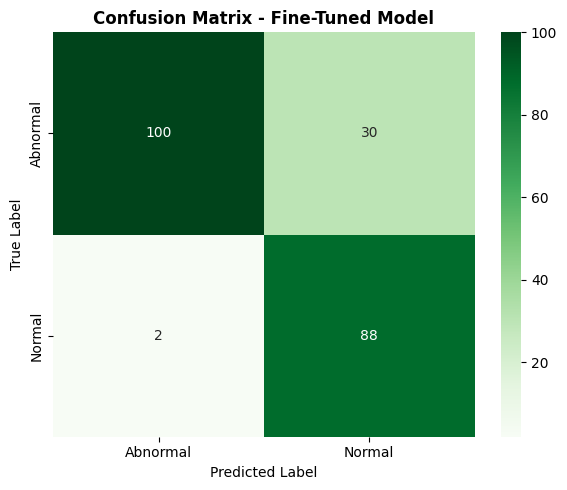

In [21]:
from sklearn.metrics import classification_report, confusion_matrix

val_generator.reset()
y_pred_probs = model.predict(val_generator)
y_true = val_generator.classes
class_names = list(val_generator.class_indices.keys())

y_pred = (y_pred_probs > 0.5).astype(int).reshape(-1)

print("Classification Report (Phase 2):")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Fine-Tuned Model', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()